# Bài 1D — Regularization & Pruning Trong Decision Tree

## 1. Mục Tiêu Bài Học
- **Hiểu bản chất của Regularization (Điều hòa):** Cách áp đặt các ràng buộc toán học để kiểm soát dung lượng mô hình, ngăn chặn Overfitting.
- **Khảo sát toàn diện hai trường phái kiểm soát độ phức tạp trong Decision Tree:**
  1. **Pre-pruning (Tỉa sớm / Early Stopping):** Ràng buộc điều kiện dừng trước khi phân nhánh: khảo sát độc lập `min_samples_split` và `min_samples_leaf`.
  2. **Post-pruning (Tỉa muộn / Cost-Complexity Pruning - CCP):** Cho cây phát triển tối đa, sau đó áp dụng hàm phạt chi phí $R_\alpha(T) = R(T) + \alpha |T|$ để cắt tỉa các nhánh kém hiệu quả.
- **Đánh giá đa chiều & Kỹ thuật chọn mô hình:** So sánh sự khác biệt giữa cấu hình tối ưu theo **ROC-AUC** và **Average Precision (AP)** dưới góc nhìn chi phí kinh doanh của ngân hàng.
- **Kỷ luật Machine Learning:** Toàn bộ quá trình chọn siêu tham số điều hòa được thực hiện trên Train/Validation. **Tập Test tiếp tục được niêm phong hoàn toàn**.

## 2. Chuẩn Bị Dữ Liệu & Mã Hóa Đặc Trưng
Kế thừa dữ liệu phân tầng từ Bài 1B (loại bỏ `duration` để chống rò rỉ dữ liệu, One-Hot Encoding chỉ fit trên Train).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display

# 1. Đọc dữ liệu
data_path = Path("data/raw/bank-additional-full.csv")
if Path.cwd().name == "notebooks":
    data_path = Path("../data/raw/bank-additional-full.csv")

df = pd.read_csv(data_path, sep=";")
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# 2. Phân chia phân tầng
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
val_ratio = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio, random_state=42, stratify=y_temp
)

# 3. Mã hóa OneHot (fit duy nhất trên Train)
cat_cols = X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[cat_cols])

X_train_encoded = np.hstack([X_train[num_cols].values, encoder.transform(X_train[cat_cols])])
X_val_encoded = np.hstack([X_val[num_cols].values, encoder.transform(X_val[cat_cols])])

print(f"X_train: {X_train_encoded.shape}, X_val: {X_val_encoded.shape}")

X_train: (28830, 62), X_val: (6179, 62)


## 3. Chiến Lược 1: Pre-Pruning (Tỉa Sớm)

Hai siêu tham số cốt lõi khống chế kích thước nút trong Pre-pruning:
- **`min_samples_split`:** Số lượng mẫu tối thiểu cần có **tại nút cha** để cho phép xem xét phân nhánh.
- **`min_samples_leaf`:** Số lượng mẫu tối thiểu bắt buộc phải có **ở mỗi nút lá con** sau khi phân nhánh.

Chúng ta sẽ thực hiện 2 thí nghiệm riêng biệt để quan sát tác động độc lập của từng siêu tham số.

### 3.1. Thí nghiệm Pre-pruning với `min_samples_split` (Cố định `min_samples_leaf = 1`)

In [2]:
split_values = [2, 10, 20, 50, 100, 200, 500, 1000]
split_results = []

for s in split_values:
    dt = DecisionTreeClassifier(random_state=42, min_samples_split=s, min_samples_leaf=1)
    dt.fit(X_train_encoded, y_train)
    
    tr_proba = dt.predict_proba(X_train_encoded)[:, 1]
    va_proba = dt.predict_proba(X_val_encoded)[:, 1]
    
    tr_auc = roc_auc_score(y_train, tr_proba)
    va_auc = roc_auc_score(y_val, va_proba)
    tr_pr = average_precision_score(y_train, tr_proba)
    va_pr = average_precision_score(y_val, va_proba)
    
    split_results.append({
        "min_samples_split": s,
        "Số nút (Nodes)": dt.tree_.node_count,
        "Số lá (Leaves)": dt.get_n_leaves(),
        "Train ROC-AUC": round(tr_auc, 4),
        "Val ROC-AUC": round(va_auc, 4),
        "Train AP": round(tr_pr, 4),
        "Val AP": round(va_pr, 4)
    })

split_df = pd.DataFrame(split_results)
display(split_df)

,min_samples_split,Số nút (Nodes),Số lá (Leaves),Train ROC-AUC,Val ROC-AUC,Train AP,Val AP
0,2,8671,4336,0.9999,0.6076,0.9986,0.1674
1,10,4705,2353,0.9767,0.6551,0.8459,0.2304
2,20,3345,1673,0.9542,0.6911,0.7478,0.2767
3,50,1957,979,0.9179,0.7414,0.6331,0.3431
4,100,1165,583,0.8877,0.7562,0.5642,0.3887
5,200,669,335,0.8613,0.7651,0.5211,0.4107
6,500,307,154,0.8363,0.7790,0.4764,0.4302
7,1000,167,84,0.8209,0.7858,0.4446,0.4178


### 3.2. Thí nghiệm Pre-pruning với `min_samples_leaf` (Cố định `min_samples_split = 2`)

In [3]:
leaf_values = [1, 5, 10, 20, 50, 100, 200, 500]
leaf_results = []

for leaf in leaf_values:
    dt = DecisionTreeClassifier(random_state=42, min_samples_leaf=leaf, min_samples_split=2)
    dt.fit(X_train_encoded, y_train)
    
    tr_proba = dt.predict_proba(X_train_encoded)[:, 1]
    va_proba = dt.predict_proba(X_val_encoded)[:, 1]
    
    tr_auc = roc_auc_score(y_train, tr_proba)
    va_auc = roc_auc_score(y_val, va_proba)
    tr_pr = average_precision_score(y_train, tr_proba)
    va_pr = average_precision_score(y_val, va_proba)
    
    leaf_results.append({
        "min_samples_leaf": leaf,
        "Số nút (Nodes)": dt.tree_.node_count,
        "Số lá (Leaves)": dt.get_n_leaves(),
        "Train ROC-AUC": round(tr_auc, 4),
        "Val ROC-AUC": round(va_auc, 4),
        "Train AP": round(tr_pr, 4),
        "Val AP": round(va_pr, 4)
    })

leaf_df = pd.DataFrame(leaf_results)
display(leaf_df)

,min_samples_leaf,Số nút (Nodes),Số lá (Leaves),Train ROC-AUC,Val ROC-AUC,Train AP,Val AP
0,1,8671,4336,0.9999,0.6076,0.9986,0.1674
1,5,4187,2094,0.9582,0.6953,0.7485,0.2935
2,10,2705,1353,0.9283,0.7223,0.6479,0.3527
3,20,1621,811,0.8984,0.7438,0.5725,0.3905
4,50,815,408,0.8619,0.7562,0.5165,0.4260
5,100,425,213,0.8416,0.7718,0.4863,0.4300
6,200,217,109,0.8230,0.7812,0.4609,0.4216
7,500,85,43,0.8003,0.7758,0.4146,0.3915


### 3.3. So Sánh min_samples_split vs min_samples_leaf & Phân Tích Lựa Chọn Mô Hình

1. **Sự khác nhau cơ chế giữa `split` và `leaf`:**
   - `min_samples_split` chỉ đòi hỏi nút cha đủ mẫu trước khi tách. Nếu phép tách phân chia không đều (ví dụ 499 mẫu sang nhánh trái, 1 mẫu sang nhánh phải), cây vẫn tạo ra một lá đơn lẻ có đúng 1 mẫu. Do đó, nguy cơ học vẹt mẫu cá biệt vẫn còn.
   - `min_samples_leaf` là điều kiện kiểm soát **nghiêm ngặt hơn**: mọi lá con sinh ra đều phải có ít nhất $M$ mẫu. Nếu có bất kỳ lá nào $< M$, phép tách bị hủy bỏ. Vì thế `min_samples_leaf` làm mượt mặt phân cách quyết định tốt hơn.

2. **Lựa chọn mô hình: ROC-AUC vs Average Precision (AP):**
   - Quan sát bảng `leaf_df`:
     - Cấu hình cho **Val ROC-AUC cao nhất là `min_samples_leaf = 200`** (AUC = 0.7812, AP = 0.4216).
     - Cấu hình cho **Val AP cao nhất là `min_samples_leaf = 100`** (AP = **0.4300**, AUC = 0.7718).
   - **Ngân hàng nên chọn cấu hình nào?**
     - **Bản chất của bài toán kinh doanh:** Mục tiêu của ngân hàng là lập danh sách gọi điện telesales cho những khách hàng thực sự có khả năng gửi tiền (`yes`). Nguồn lực gọi điện là có hạn, mỗi cuộc gọi đều tốn chi phí lương nhân viên và cước viễn thông.
     - **Chi phí sai sót (*Error Costs*):**
       - False Positive (FP): Gọi nhầm người từ chối $\rightarrow$ tốn chi phí cuộc gọi, làm phiền khách hàng.
       - False Negative (FN): Bỏ sót khách hàng muốn gửi tiền $\rightarrow$ mất doanh thu lãi biên từ khoản tiền gửi.
     - **Tại sao AP là tiêu chuẩn ưu tiên hơn ROC-AUC?**
       - ROC-AUC đo khả năng xếp hạng tổng thể trên toàn bộ dữ liệu, bị chi phối mạnh bởi số lượng mẫu âm đa số ($TN$).
       - Average Precision (AP) tập trung toàn bộ vào mối quan hệ giữa Precision (gọi trúng bao nhiêu %) và Recall (bắt được bao nhiêu % khách hàng tiềm năng). Vì vậy, với mục tiêu telesales hiệu quả, cấu hình đạt **Val AP cao nhất (`min_samples_leaf = 100`)** là lựa chọn kinh doanh thuyết phục hơn.
   - **Lưu ý kỹ thuật:** `average_precision_score` trong scikit-learn tính Average Precision (AP) theo tổng Riemann có trọng số: $\text{AP} = \sum_n (R_n - R_{n-1}) P_n$. Cách tính này tránh được việc phóng đại diện tích của quy tắc hình thang (*trapezoidal rule*) khi đường Precision-Recall có các bước nhảy bậc thang.

## 4. Chiến Lược 2: Post-Pruning Bằng Cost-Complexity Pruning (CCP)

Cost-Complexity Pruning (Breiman et al. - CART) giải quyết bài toán tối ưu hóa đa mục tiêu:
$$R_\alpha(T) = R(T) + \alpha |T|$$
- $R(T)$: Tổng sai số bất thuần trên tập huấn luyện.
- $|T|$: Số lượng nút lá của cây.
- $\alpha$ (`ccp_alpha`): Hệ số phạt kích thước cây. $\alpha = 0$ là cây ban đầu, $\alpha$ càng lớn thì cây bị tỉa càng mạnh.

In [4]:
# 1. Trích xuất lộ trình tỉa cành (Pruning Path)
full_tree = DecisionTreeClassifier(random_state=42)
path = full_tree.cost_complexity_pruning_path(X_train_encoded, y_train)
ccp_alphas = path.ccp_alphas

print(f"Tổng số mốc alpha tìm thấy trong lộ trình: {len(ccp_alphas)}")
print(f"Alpha nhỏ nhất: {ccp_alphas[0]:.6f}, Alpha lớn nhất: {ccp_alphas[-1]:.6f}")

# 2. Khảo sát một tập hợp các giá trị alpha đại diện
test_alphas = [0.0, 0.0001, 0.0002, 0.0003, 0.0005, 0.0007, 0.001, 0.0015, 0.002, 0.005]
post_results = []

for a in test_alphas:
    dt = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    dt.fit(X_train_encoded, y_train)
    
    tr_proba = dt.predict_proba(X_train_encoded)[:, 1]
    va_proba = dt.predict_proba(X_val_encoded)[:, 1]
    
    tr_auc = roc_auc_score(y_train, tr_proba)
    va_auc = roc_auc_score(y_val, va_proba)
    tr_pr = average_precision_score(y_train, tr_proba)
    va_pr = average_precision_score(y_val, va_proba)
    
    post_results.append({
        "ccp_alpha": a,
        "Số nút (Nodes)": dt.tree_.node_count,
        "Số lá (Leaves)": dt.get_n_leaves(),
        "Train ROC-AUC": round(tr_auc, 4),
        "Val ROC-AUC": round(va_auc, 4),
        "Train AP": round(tr_pr, 4),
        "Val AP": round(va_pr, 4)
    })

post_df = pd.DataFrame(post_results)
display(post_df)

Tổng số mốc alpha tìm thấy trong lộ trình: 1287
Alpha nhỏ nhất: 0.000000, Alpha lớn nhất: 0.029859


,ccp_alpha,Số nút (Nodes),Số lá (Leaves),Train ROC-AUC,Val ROC-AUC,Train AP,Val AP
0,0.0000,8671,4336,0.9999,0.6076,0.9986,0.1674
1,0.0001,137,69,0.7972,0.7763,0.4736,0.4037
2,0.0002,37,19,0.7905,0.7770,0.4342,0.4171
3,0.0003,33,17,0.7848,0.7732,0.4220,0.4075
4,0.0005,21,11,0.7592,0.7494,0.3942,0.3788
5,0.0007,13,7,0.7526,0.7452,0.3695,0.3575
6,0.0010,11,6,0.7484,0.7390,0.3643,0.3491
7,0.0015,7,4,0.7460,0.7374,0.3480,0.3368
8,0.0020,7,4,0.7460,0.7374,0.3480,0.3368
9,0.0050,5,3,0.7041,0.7004,0.3173,0.3094


## 5. Trực Quan Hóa Quá Trình Tỉa Cành: Toàn Cảnh & Cận Cảnh Vùng Alpha Nhỏ

Do $\alpha$ trải dài từ 0 đến 0.005, thang đo tuyến tính sẽ nén các giá trị $\alpha$ nhỏ vào một góc hẹp.
Dưới đây, chúng ta xây dựng 2 góc nhìn:
1. **Góc nhìn 1:** Toàn cảnh diễn biến số lá và hiệu năng trên dải $\alpha \in [0, 0.005]$.
2. **Góc nhìn 2 (Zoom Cận Cảnh):** Phóng to vùng $\alpha \le 0.001$, nơi hiệu năng thay đổi mạnh mẽ nhất, với điểm tối ưu được **trích xuất tự động từ bảng dữ liệu**.

Alpha tối ưu theo Val ROC-AUC: 0.0002 (Score: 0.777)
Alpha tối ưu theo Val AP:      0.0002 (Score: 0.4171)


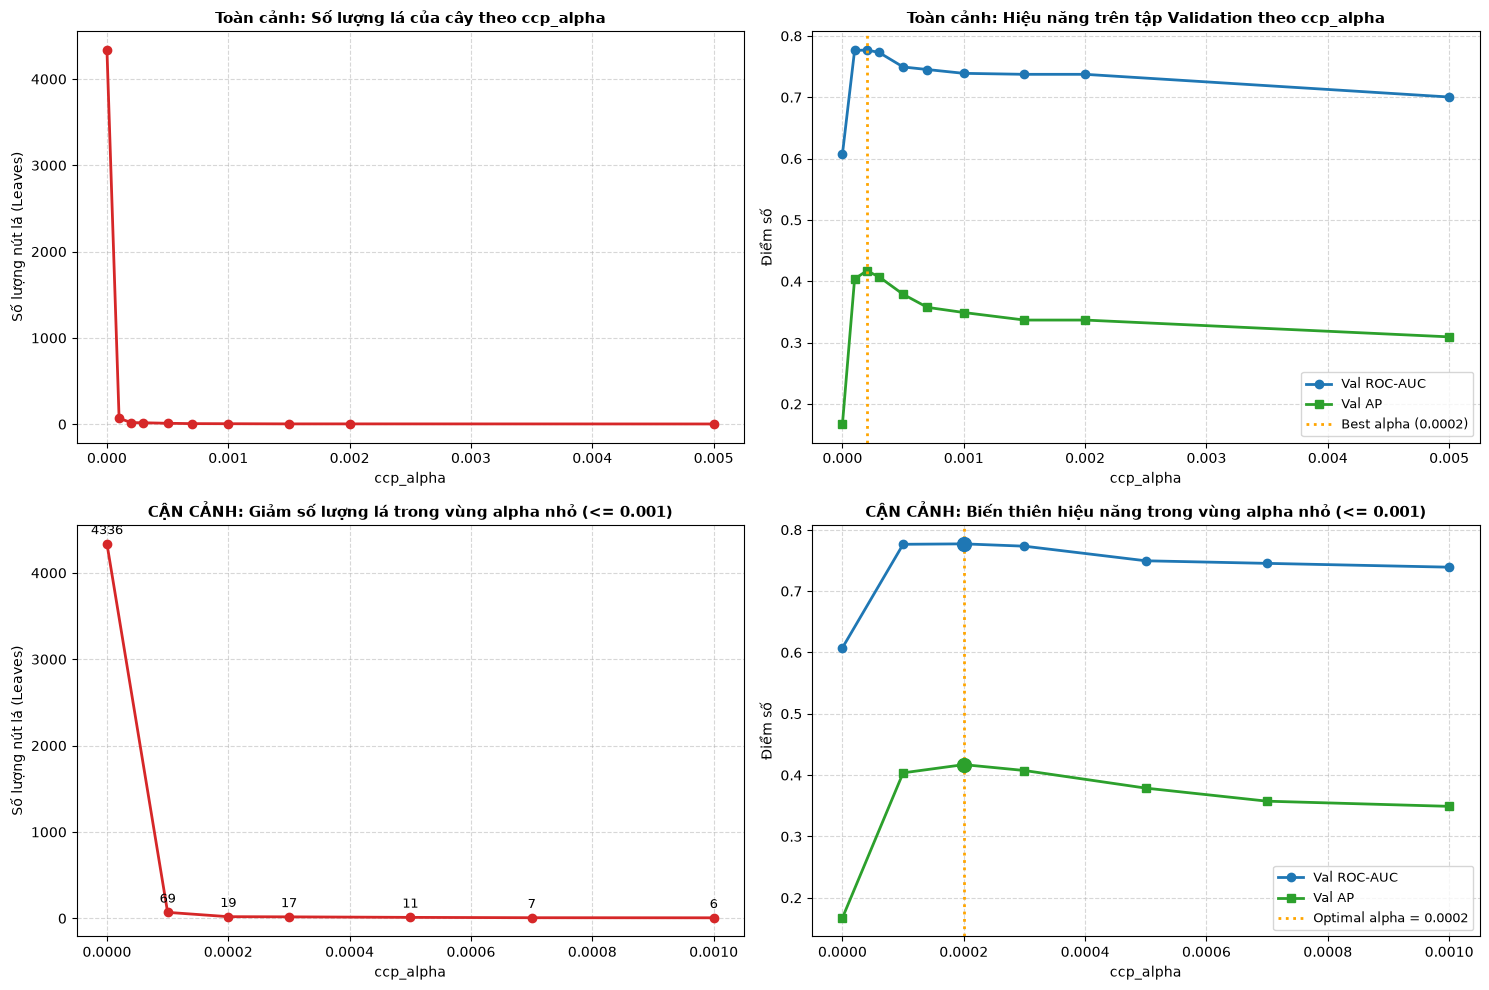

In [5]:
# Trích xuất tự động cấu hình alpha tối ưu từ bảng kết quả
best_idx_auc = post_df["Val ROC-AUC"].idxmax()
best_alpha_auc = post_df.loc[best_idx_auc, "ccp_alpha"]
best_val_auc = post_df.loc[best_idx_auc, "Val ROC-AUC"]

best_idx_ap = post_df["Val AP"].idxmax()
best_alpha_ap = post_df.loc[best_idx_ap, "ccp_alpha"]
best_val_ap = post_df.loc[best_idx_ap, "Val AP"]

print(f"Alpha tối ưu theo Val ROC-AUC: {best_alpha_auc} (Score: {best_val_auc})")
print(f"Alpha tối ưu theo Val AP:      {best_alpha_ap} (Score: {best_val_ap})")

# Tạo lưới biểu đồ 2 hàng x 2 cột
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Hàng 1 - Trái: Toàn cảnh số lượng lá theo alpha (0 đến 0.005)
axes[0, 0].plot(post_df["ccp_alpha"], post_df["Số lá (Leaves)"], marker="o", color="#d62728", linewidth=2)
axes[0, 0].set_title("Toàn cảnh: Số lượng lá của cây theo ccp_alpha", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("ccp_alpha", fontsize=10)
axes[0, 0].set_ylabel("Số lượng nút lá (Leaves)", fontsize=10)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Hàng 1 - Phải: Toàn cảnh hiệu năng ROC-AUC và AP theo alpha (0 đến 0.005)
axes[0, 1].plot(post_df["ccp_alpha"], post_df["Val ROC-AUC"], marker="o", label="Val ROC-AUC", color="#1f77b4", linewidth=2)
axes[0, 1].plot(post_df["ccp_alpha"], post_df["Val AP"], marker="s", label="Val AP", color="#2ca02c", linewidth=2)
axes[0, 1].axvline(x=best_alpha_auc, color="orange", linestyle=":", linewidth=2, label=f"Best alpha ({best_alpha_auc})")
axes[0, 1].set_title("Toàn cảnh: Hiệu năng trên tập Validation theo ccp_alpha", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("ccp_alpha", fontsize=10)
axes[0, 1].set_ylabel("Điểm số", fontsize=10)
axes[0, 1].grid(True, linestyle="--", alpha=0.5)
axes[0, 1].legend(fontsize=9)

# Hàng 2: Phóng to (Zoom-in) vùng alpha nhỏ <= 0.001
zoom_df = post_df[post_df["ccp_alpha"] <= 0.001]

# Hàng 2 - Trái: Cận cảnh số lá trong vùng alpha nhỏ
axes[1, 0].plot(zoom_df["ccp_alpha"], zoom_df["Số lá (Leaves)"], marker="o", color="#d62728", linewidth=2)
for _, row in zoom_df.iterrows():
    axes[1, 0].annotate(f"{int(row['Số lá (Leaves)'])}", (row["ccp_alpha"], row["Số lá (Leaves)"]),
                        textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
axes[1, 0].set_title("CẬN CẢNH: Giảm số lượng lá trong vùng alpha nhỏ (<= 0.001)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("ccp_alpha", fontsize=10)
axes[1, 0].set_ylabel("Số lượng nút lá (Leaves)", fontsize=10)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Hàng 2 - Phải: Cận cảnh hiệu năng Val ROC-AUC và Val AP trong vùng alpha nhỏ
axes[1, 1].plot(zoom_df["ccp_alpha"], zoom_df["Val ROC-AUC"], marker="o", label="Val ROC-AUC", color="#1f77b4", linewidth=2)
axes[1, 1].plot(zoom_df["ccp_alpha"], zoom_df["Val AP"], marker="s", label="Val AP", color="#2ca02c", linewidth=2)
axes[1, 1].axvline(x=best_alpha_auc, color="orange", linestyle=":", linewidth=2, label=f"Optimal alpha = {best_alpha_auc}")
axes[1, 1].scatter([best_alpha_auc], [best_val_auc], color="#1f77b4", s=100, zorder=5)
axes[1, 1].scatter([best_alpha_ap], [best_val_ap], color="#2ca02c", s=100, zorder=5)
axes[1, 1].set_title("CẬN CẢNH: Biến thiên hiệu năng trong vùng alpha nhỏ (<= 0.001)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("ccp_alpha", fontsize=10)
axes[1, 1].set_ylabel("Điểm số", fontsize=10)
axes[1, 1].grid(True, linestyle="--", alpha=0.5)
axes[1, 1].legend(fontsize=9)

plt.tight_layout()
plt.show()

## 6. Phân Tích Bản Chất Thuật Toán: Pre-Pruning vs Post-Pruning

### 1. Post-Pruning Có Khắc Phục Được Thuật Toán Tham Lam Không?
- **Câu trả lời dứt khoát: KHÔNG.**
- **Bản chất toán học:** Cây quyết định ban đầu vẫn được xây dựng bằng thuật toán **tham lam từ trên xuống (top-down greedy search)**. Tại mỗi nút, thuật toán chỉ chọn phép chia tốt nhất cục bộ (locally optimal split) để tối đa hóa độ giảm bất thuần ngay tại bước đó.
- **Hạn chế cố hữu:** Nếu một phép chia hữu ích bị bỏ qua ở các bước đầu (ví dụ: bài toán tương tác biến phức tạp dạng XOR, nơi từng biến đơn lẻ không làm giảm impurity), cây ban đầu sẽ không tạo ra nhánh đó. **Post-Pruning chỉ cắt bỏ các nhánh đã tồn tại trong cây, nó không thể hồi sinh hay sáng tạo ra một phép chia mới mà thuật toán tham lam đã bỏ lỡ**.
- **Vậy Post-Pruning thực sự giải quyết được điều gì?** Nó giải quyết nhược điểm **dừng quá sớm (*horizon effect / premature stopping*)** của Pre-pruning: thay vì đoán trước liệu một nhánh có triển vọng hay không để dừng sớm, Post-pruning cho phép cây phát triển tự do để xem xét các nhánh con phía sau trước khi đưa ra quyết định cắt tỉa toàn cục.

### 2. Tổng Kết So Sánh Pre-Pruning & Post-Pruning:
| Tiêu chí | Pre-Pruning (`min_samples_leaf`, `min_samples_split`) | Post-Pruning (Cost-Complexity Pruning `ccp_alpha`) |
| :--- | :--- | :--- |
| **Cơ chế** | Chặn phân nhánh sớm (*Early Stopping*) | Cho mọc đầy đủ rồi tỉa ngược từ dưới lên |
| **Thuật toán tìm nhát cắt** | Tham lam cục bộ (*Greedy Search*) | Vẫn là tham lam cục bộ ở bước dựng cây ban đầu |
| **Rủi ro dừng sớm (*Horizon Effect*)** | Có: có thể bỏ lỡ các nhánh sâu hữu ích | Khắc phục được rủi ro dừng sớm |
| **Chi phí tính toán** | Thấp, tiết kiệm bộ nhớ, thích hợp cho Ensemble | Cao, phải dựng cây lớn trước khi tính toán path |
| **Mô hình tối ưu trên Val** | `min_samples_leaf = 100` (Val AP = 0.4300) | `ccp_alpha = 0.0002` (Val AP = 0.4171, 19 lá) |